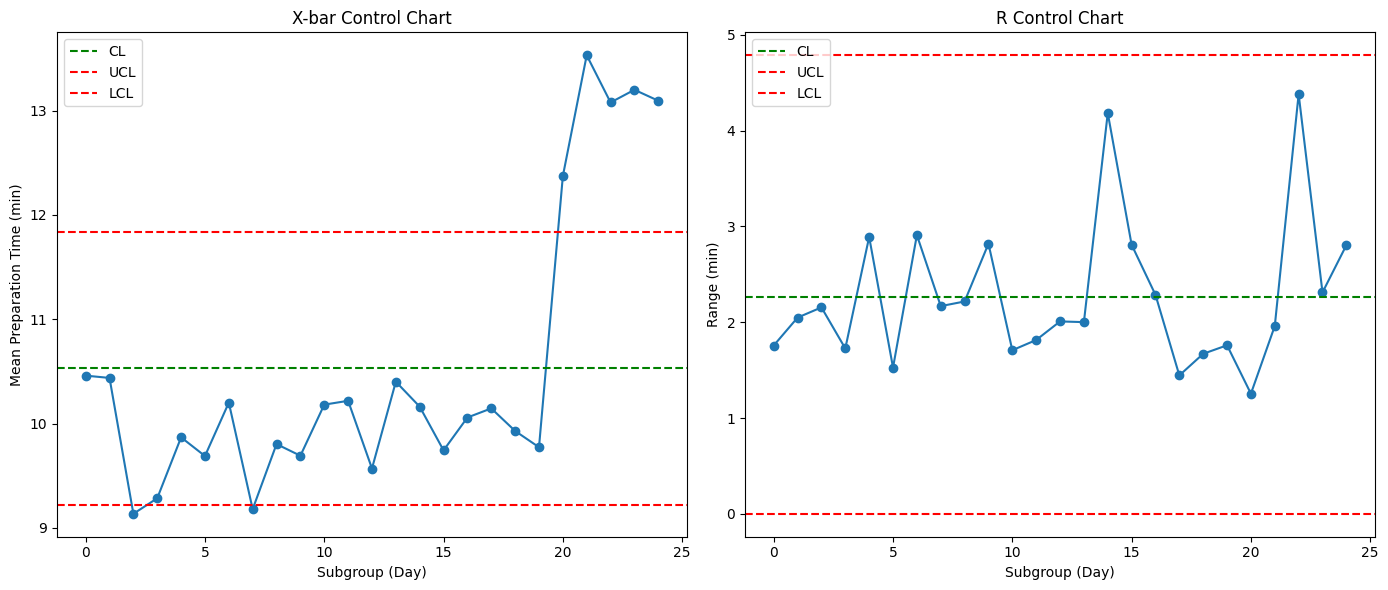

In [ ]:
#Task_1
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
subgroups = 25
subgroup_size = 5
data = np.random.normal(10, 1, size=(subgroups, subgroup_size))
data[-5:] += 3   # shift mean upward by +3 minutes


def create_control_charts(data, subgroup_size):
    # SPC CONSTANTS FOR n = 5 (standard table)
    A2 = 0.577
    D3 = 0      # for n=5
    D4 = 2.114  # for n=5

    # Compute subgroup statistics
    subgroup_means = data.mean(axis=1)
    subgroup_ranges = data.max(axis=1) - data.min(axis=1)

    X_double_bar = subgroup_means.mean()     # grand mean of means
    R_bar = subgroup_ranges.mean()           # average range

    # Control Limits
    UCL_X = X_double_bar + A2 * R_bar
    LCL_X = X_double_bar - A2 * R_bar

    UCL_R = D4 * R_bar
    LCL_R = D3 * R_bar

    results = {
        "means": subgroup_means,
        "ranges": subgroup_ranges,
        "X_double_bar": X_double_bar,
        "R_bar": R_bar,
        "UCL_X": UCL_X,
        "LCL_X": LCL_X,
        "UCL_R": UCL_R,
        "LCL_R": LCL_R
    }
    return results


results = create_control_charts(data, subgroup_size)
means = results["means"]
ranges = results["ranges"]

plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
plt.plot(means, marker='o')
plt.axhline(results["X_double_bar"], color='green', linestyle='--', label='CL')
plt.axhline(results["UCL_X"], color='red', linestyle='--', label='UCL')
plt.axhline(results["LCL_X"], color='red', linestyle='--', label='LCL')
plt.title("X-bar Control Chart")
plt.xlabel("Subgroup (Day)")
plt.ylabel("Mean Preparation Time (min)")
plt.legend()
plt.subplot(1,2,2)
plt.plot(ranges, marker='o')
plt.axhline(results["R_bar"], color='green', linestyle='--', label='CL')
plt.axhline(results["UCL_R"], color='red', linestyle='--', label='UCL')
plt.axhline(results["LCL_R"], color='red', linestyle='--', label='LCL')
plt.title("R Control Chart")
plt.xlabel("Subgroup (Day)")
plt.ylabel("Range (min)")
plt.legend()
plt.tight_layout()
plt.show()


In days 21–25, the pharmacy process becomes unstable due to a sudden increase in preparation time.
The X-bar chart detects this clearly with multiple points above the UCL, while the R chart stays normal because the within-subgroup variability did not increase.
This indicates a shift in process center, not process spread.

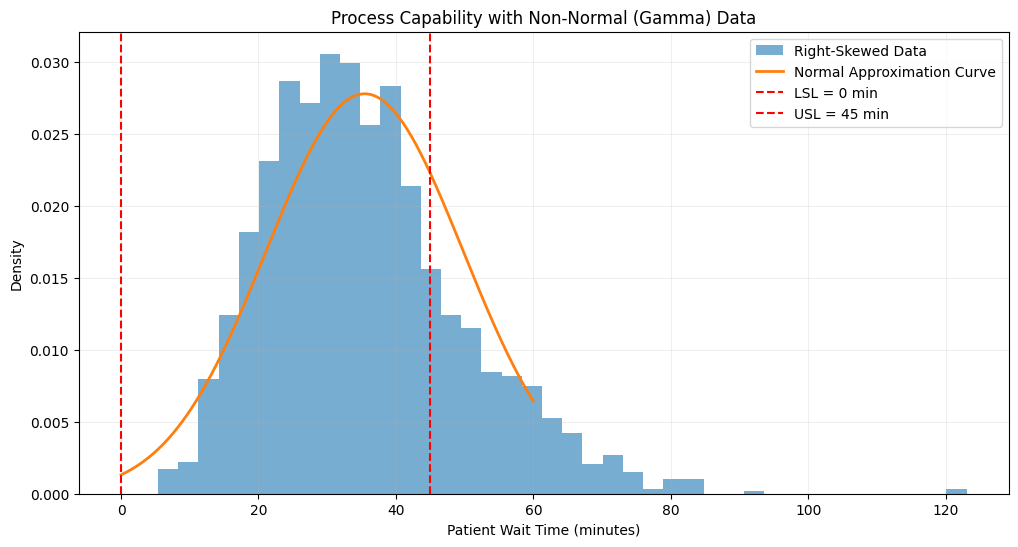

Mean (μ): 35.45
Std Dev (σ): 14.35
Cp: 0.523
Cpk: 0.222

Normal-Theory DPMO: 259611.8
Normal-Theory Yield: 74.04%

TRUE DPMO from Actual Data: 220500.0
TRUE Yield from Actual Data: 77.95%


In [ ]:
#Task_2
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma, norm

np.random.seed(42)

# Specification limits
USL = 45   # upper spec limit (minutes)
LSL = 0    # lower spec limit

# Target mean and std deviation
target_mean = 35
target_std = 7
shape = 6
scale = target_mean / shape

data = gamma.rvs(a=shape, scale=scale, size=2000)

mu = np.mean(data)
sigma = np.std(data)

def capability_indices(mu, sigma, USL, LSL):
    Cp = (USL - LSL) / (6 * sigma)
    Cpk = min((USL - mu) / (3 * sigma), (mu - LSL) / (3 * sigma))
    return Cp, Cpk


def calculate_dpmo_and_yield(mu, sigma, USL, LSL):
    # Normal-theory (assumes data is normal)
    p_defect = 1 - (norm.cdf(USL, mu, sigma) - norm.cdf(LSL, mu, sigma))
    dpmo_normal = p_defect * 1_000_000
    yield_normal = (1 - p_defect)

    # TRUE DPMO from the actual skewed data
    true_defects = np.sum((data > USL) | (data < LSL))
    dpmo_true = (true_defects / len(data)) * 1_000_000
    yield_true = 1 - (true_defects / len(data))

    return dpmo_normal, yield_normal, dpmo_true, yield_true


Cp, Cpk = capability_indices(mu, sigma, USL, LSL)
dpmo_normal, yield_normal, dpmo_true, yield_true = calculate_dpmo_and_yield(mu, sigma, USL, LSL)

plt.figure(figsize=(12,6))
plt.hist(data, bins=40, density=True, alpha=0.6, label="Right-Skewed Data")
xmin, xmax = 0, 60
x = np.linspace(xmin, xmax, 500)
pdf_normal = norm.pdf(x, mu, sigma)
plt.plot(x, pdf_normal, linewidth=2, label="Normal Approximation Curve")
plt.axvline(LSL, color='red', linestyle='--', label="LSL = 0 min")
plt.axvline(USL, color='red', linestyle='--', label="USL = 45 min")

plt.title("Process Capability with Non-Normal (Gamma) Data")
plt.xlabel("Patient Wait Time (minutes)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Mean (μ): {mu:.2f}")
print(f"Std Dev (σ): {sigma:.2f}")
print(f"Cp: {Cp:.3f}")
print(f"Cpk: {Cpk:.3f}")
print()
print(f"Normal-Theory DPMO: {dpmo_normal:.1f}")
print(f"Normal-Theory Yield: {yield_normal*100:.2f}%")
print()
print(f"TRUE DPMO from Actual Data: {dpmo_true:.1f}")
print(f"TRUE Yield from Actual Data: {yield_true*100:.2f}%")

Cp < 1 → Process spread is too wide relative to the tolerance band.
Cpk very small → Mean is too close to USL, process not centered.
The capability analysis shows that the process is not capable (Cp = 0.523), and the mean is too close to the upper specification limit (Cpk = 0.222).
When calculating DPMO assuming normality, the estimated defect rate (259,612 per million) is higher than the true defect rate from the actual non-normal data (220,500 per million).
This demonstrates that assuming a normal distribution can misrepresent the true capability, especially for right-skewed healthcare processes such as patient wait times. Normal-based estimates exaggerate tail probabilities and produce misleading capability indices.

Average Value Added Ratio (VAR): 0.381
Average Total Cycle Time (TCT): 56.22 min

Average Non-Value-Added Times:
Wait_1_Time: 15.54 min
Wait_2_Time: 19.66 min

➡ Largest Bottleneck: Wait_2_Time (19.66 min)


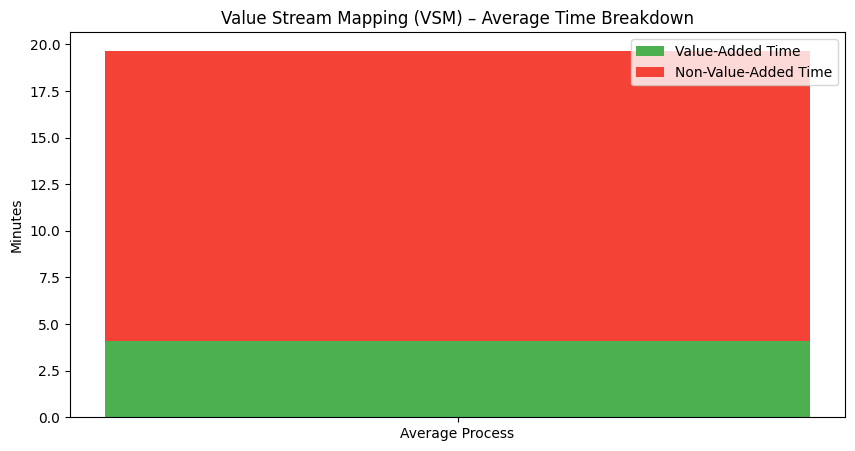


IMPROVEMENT SIMULATION
Original Avg TCT: 56.22 min
New Avg TCT after 40% reduction: 48.36 min
Original Avg VAR: 0.381
New Avg VAR after 40% reduction: 0.441


In [ ]:
#Task_3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 100
df = pd.DataFrame({
    "ID": range(1, n+1),

    # Value-added steps (in minutes)
    "Step_1_Time": np.random.normal(5, 1, n).clip(2, 10),     # Registration
    "Step_2_Time": np.random.normal(12, 2, n).clip(8, 20),    # Imaging scan
    "Step_3_Time": np.random.normal(4, 1, n).clip(2, 8),      # Review/Discharge

    # Non-value-added waiting times
    "Wait_1_Time": np.random.normal(15, 5, n).clip(5, 40),    # Waiting for room
    "Wait_2_Time": np.random.normal(20, 6, n).clip(5, 50)     # Waiting for radiologist
})

df["TCT"] = df[[
    "Step_1_Time","Wait_1_Time","Step_2_Time","Wait_2_Time","Step_3_Time"
]].sum(axis=1)

df["VAT"] = df[["Step_1_Time","Step_2_Time","Step_3_Time"]].sum(axis=1)

df["VAR"] = df["VAT"] / df["TCT"]

avg_VAR = df["VAR"].mean()
avg_TCT = df["TCT"].mean()

print(f"Average Value Added Ratio (VAR): {avg_VAR:.3f}")
print(f"Average Total Cycle Time (TCT): {avg_TCT:.2f} min")

avg_waits = {
    "Wait_1_Time": df["Wait_1_Time"].mean(),
    "Wait_2_Time": df["Wait_2_Time"].mean()
}

bottleneck = max(avg_waits, key=avg_waits.get)

print("\nAverage Non-Value-Added Times:")
for k, v in avg_waits.items():
    print(f"{k}: {v:.2f} min")

print(f"\n Largest Bottleneck: {bottleneck} ({avg_waits[bottleneck]:.2f} min)")
avg_times = [
    df["Step_1_Time"].mean(),
    df["Wait_1_Time"].mean(),
    df["Step_2_Time"].mean(),
    df["Wait_2_Time"].mean(),
    df["Step_3_Time"].mean()
]

labels = ["Step 1 (VA)", "Wait 1 (NVA)", "Step 2 (VA)", "Wait 2 (NVA)", "Step 3 (VA)"]
colors = ["#4CAF50", "#F44336", "#4CAF50", "#F44336", "#4CAF50"]  # Green=VA, Red=NVA

plt.figure(figsize=(10,5))
plt.bar(["Average Process"], avg_times, color=colors, label=labels)

# Add legend manually
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4CAF50", label="Value-Added Time"),
    Patch(facecolor="#F44336", label="Non-Value-Added Time")
]
plt.legend(handles=legend_elements, loc="upper right")

plt.title("Value Stream Mapping (VSM) – Average Time Breakdown")
plt.ylabel("Minutes")
plt.show()

def simulate_improvement(df, bottleneck_col, reduction_pct=0.4):
    df2 = df.copy()
    df2[bottleneck_col] = df2[bottleneck_col] * (1 - reduction_pct)

    df2["TCT"] = df2[[
        "Step_1_Time","Wait_1_Time","Step_2_Time","Wait_2_Time","Step_3_Time"
    ]].sum(axis=1)

    df2["VAT"] = df2[["Step_1_Time","Step_2_Time","Step_3_Time"]].sum(axis=1)
    df2["VAR"] = df2["VAT"] / df2["TCT"]

    return df2["TCT"].mean(), df2["VAR"].mean()

new_TCT, new_VAR = simulate_improvement(df, bottleneck)

print("\nIMPROVEMENT SIMULATION")
print(f"Original Avg TCT: {avg_TCT:.2f} min")
print(f"New Avg TCT after 40% reduction: {new_TCT:.2f} min")
print(f"Original Avg VAR: {avg_VAR:.3f}")
print(f"New Avg VAR after 40% reduction: {new_VAR:.3f}")

the average Total Cycle Time (TCT) is 56.22 minutes, but only 38% of that time is Value-Added (steps such as registration, scanning, and review). The remaining time is spent waiting—mainly in Wait_2_Time, where patients wait an average of 19.66 minutes for the radiologist review, making it the largest bottleneck. The stacked bar chart visually highlights this imbalance, with Non-Value-Added time forming the majority of the workflow. When applying a Lean improvement that reduces the largest bottleneck by 40%, the process becomes significantly more efficient: the average TCT decreases to 48.36 minutes, and the Value-Added Ratio improves from 0.381 to 0.441, clearly demonstrating the impact of eliminating waste in the process